The foundational equations for pricing claims can be found at the bottom of this file


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import scipy.stats as stats
from matplotlib.ticker import FuncFormatter

from sklearn import svm

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance

from sklearn.model_selection import KFold, GroupKFold, cross_validate, train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from datetime import datetime

import os
import sys

from configparser import ConfigParser
from pathlib import Path

# Sets the working directory so that the key files can be imported
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src" / "insurance_pricing").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

os.chdir(PROJECT_ROOT)

# Make your source package importable
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from Insurance_pricing.data import Find_N_datasets, inspect_dataset, Dates_to_times, plot_df
from Insurance_pricing.cleaning import clean_types, clean_dates

Risk is defined to be "the potential that actual financial or operational outcomes will differ from the assumptions, models, and estimates used by actuaries."

It can be calcuated using a number of equations however for this project. We will focus primarily on:

**The Collective Risk Model**

$$S = \sum_{i=1}^{N}{X_i}$$
*Total expected losses \(S\), the frequency of claims \(N\), the severity of claims \(X\).*

**General Linear Models \(GLMs\)**


In [29]:
paths = Find_N_datasets(N_files=2, path_loc='processed')
motor = pd.read_csv(paths[0], sep=";")
claims = pd.read_csv(paths[1], sep=";")

motor_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Processed\Motor_Clean.csv
claims_data: C:\Users\alloh\OneDrive\Documents\Github\Motor-Insurance-Claims-Prediction-and-Pricing\Data\Processed\Claims_Clean.csv


In [30]:
motor.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Young_Policy_Maker,Contract_Terminated,Is_Motorbike,Is_Van,Is_Passenger_Car,Is_Agricultural,Fuel_Petrol,Fuel_Diesel,Type_fuel_nan,Heavy_vehicle
0,1,0,4,1,2,1,0,NaN,0,222.52,...,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
1,1,0,4,1,2,1,0,NaN,0,213.78,...,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
2,1,0,4,2,2,1,0,NaN,0,214.84,...,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
3,1,0,4,2,2,1,0,NaN,0,216.99,...,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0
4,2,0,4,2,2,1,0,NaN,1,213.70,...,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0


In [34]:
motor.columns

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment',
       'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Area', 'Second_driver', 'Year_matriculation',
       'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Length',
       'Weight', 'Date_lapse_missing', 'Fuel_Unknown', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
       'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
       'Old_Policy', 'Old_Policy_Maker', 'Young_Policy', 'Young_Policy_Maker',
       'Contract_Terminated', 'Is_Motorbike', 'Is_Van', 'Is_Passenger_Car',
       'Is_Agricultural', 'Fuel_Petrol', 'Fuel_Diesel', 'Type_fuel_nan',
       'Heavy_vehicle'],
      dtype='str')

We want to create some database for the loss history of the clients to make the data useable by underwritters.

In [ ]:
df_motor = motor.copy()
df_claims = claims.copy()

df_loss_history = pd.DataFrame()

df_loss_history['ID'] = df_claims['ID']

In [ ]:
df_claims["Total_Cost"] = df_claims.groupby("ID")["Cost_claims_year"].transform("sum")


# Sum total claim costs for each ID
total_costs = df_claims.groupby("ID")["Total_Cost"].sum()

# Map total costs onto the motor dataframe
df_motor["Total_Cost"] = df_motor["ID"].map(total_costs)

# Calculate claim severity
est_policy_range =  (df_motor["Policy_Age"].max() - df_motor["Policy_Age"].min())

df_motor["Claim_severity"] = (
    df_motor["Total_Cost"] /
    (df_motor["N_claims_year"] * est_policy_range)
    )

df_motor['Claim_frequency'] = ((df_motor['R_Claims_history'] * 
                                df_motor['Policy_Age'])/(df_motor['Policies_in_force'])
                                )

df_motor['Pure_Premium'] = (df_motor["Claim_severity"] *
                            df_motor["Claim_frequency"])

In [28]:
df_motor['N_claims_year'].unique()

array([ 0,  3,  8,  4,  1,  2,  9,  7,  6,  5, 15, 13, 10, 11, 14, 12, 18,
       19, 17, 25, 21, 16])

In [20]:
df_motor.head()

,ID,Distribution_channel,Seniority,Policies_in_force,Max_policies,Max_products,Lapse,Date_lapse,Payment,Premium,...,Is_Passenger_Car,Is_Agricultural,Fuel_Petrol,Fuel_Diesel,Type_fuel_nan,Heavy_vehicle,Total_Cost,Claim_severity,Claim_frequency,Pure Premium
0,1,0,4,1,2,1,0,NaN,0,222.52,...,0.0,0.0,0.0,1.0,0.0,0,NaN,NaN,0.0,NaN
1,1,0,4,1,2,1,0,NaN,0,213.78,...,0.0,0.0,0.0,1.0,0.0,0,NaN,NaN,0.0,NaN
2,1,0,4,2,2,1,0,NaN,0,214.84,...,0.0,0.0,0.0,1.0,0.0,0,NaN,NaN,0.0,NaN
3,1,0,4,2,2,1,0,NaN,0,216.99,...,0.0,0.0,0.0,1.0,0.0,0,NaN,NaN,0.0,NaN
4,2,0,4,2,2,1,0,NaN,1,213.70,...,0.0,0.0,0.0,1.0,0.0,0,NaN,NaN,0.0,NaN


In [19]:
df_inspect = df_motor.copy()
df_inspect.columns

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Date_lapse', 'Payment',
       'Premium', 'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Area', 'Second_driver', 'Year_matriculation',
       'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Length',
       'Weight', 'Date_lapse_missing', 'Fuel_Unknown', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
       'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
       'Old_Policy', 'Old_Policy_Maker', 'Young_Policy', 'Young_Policy_Maker',
       'Contract_Terminated', 'Is_Motorbike', 'Is_Van', 'Is_Passenger_Car',
       'Is_Agricultural', 'Fuel_Petrol', 'Fuel_Diesel', 'Type_fuel_nan',
       'Heavy_vehicle', 'Total_Cost', 'Claim_severity', 'Claim_frequency',
       'Pure Premium'],
      dtype='str')

In [8]:
df_inspect['R_Claims_history'].unique()

array([ 0.  ,  0.16,  2.  ,  0.34,  0.5 ,  4.  ,  0.2 ,  0.75,  0.36,
        0.25,  0.52,  0.69,  1.  ,  1.63,  0.56,  2.23,  2.5 ,  1.9 ,
        1.49,  0.54,  0.33,  1.67,  0.18,  0.73,  1.5 ,  2.84,  3.23,
        0.39,  0.6 ,  0.62,  0.4 ,  1.41,  0.92,  0.38,  0.42,  0.67,
        1.45,  2.02,  0.14,  2.31,  0.37,  1.05,  1.33,  2.17,  0.22,
        0.46,  1.44,  1.84,  0.29,  3.92,  1.4 ,  1.48, 20.  ,  3.26,
        0.68,  0.87,  0.27,  1.09,  0.71,  1.25,  1.18,  1.99,  1.75,
        4.03,  0.43,  0.15,  2.25,  0.23,  2.13,  0.96,  0.17,  0.8 ,
        0.99,  2.04,  2.21,  2.16,  0.59,  0.74,  1.28,  0.07,  0.64,
        0.13,  0.05,  3.  ,  0.09,  1.96,  3.3 ,  0.06,  1.32,  0.83,
        0.48,  0.7 ,  0.1 ,  1.21,  4.35,  0.44,  1.16,  1.72,  1.98,
        0.08,  0.35,  0.3 ,  0.84,  0.78,  0.47,  0.45,  0.94,  2.96,
        0.11,  0.03,  3.99,  0.26,  0.66,  0.9 ,  0.65,  1.57,  2.76,
        4.12,  0.89,  0.61,  0.31,  0.63,  0.88,  1.59,  2.33,  0.57,
        1.31,  1.3 ,

In [9]:
cols_numeric = ['Seniority', 'Policies_in_force','Lapse', 'Payment',
                'Premium','Cost_claims_year', 'N_claims_year','R_Claims_history',
                'Year_matriculation','Power', 'Cylinder_capacity', 'Value_vehicle',
                'N_doors', 'Length', 'Weight', 'Policy_Age', 
                'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age', 'Time_from_renewal',
                'Time_till_renewal', 'Renewed_period', 'Total_Cost', 'Claim_severity',
                'Claim_frequency','Pure Premium'
                ]

cols_categories = [
    'Old_Policy', 'Distribution_channel', 'Payment', 'Second_driver',
    'Old_Policy_Maker','Heavy_Vehical', 'Is_Motorbike', 'Is_Van',
    'Is_Passenger_Car', 'Area', 'Is_Agricultural', 'Fuel_Petrol',
    'Fuel_Diesel', 'Fuel_Unknown', 'Young_Policy', 'Young_Policy_Maker',
    'Contract_Terminated', 'Type_fuel_Unknown',
    'Heavy_vehicle'
    ]

inspect_mask = (
    (df_inspect[] > 0) &
    np.isfinite(df_inspect['Pure Premium'])
)

df_inspect.loc[inspect_mask,'Pure Premium']

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3085566871.py, line 20)

In [ ]:
df_inspect = df_motor.copy()
df_inspect.drop(columns=["Date_lapse"], inplace = True)

In [ ]:
df_motor['N_claims_year']

18        3
22        0
23        0
28        8
29        4
         ..
105499    0
105507    0
105508    0
105514    0
105515    0
Name: N_claims_year, Length: 35147, dtype: int64

In [ ]:
df_motor.columns

Index(['ID', 'Distribution_channel', 'Seniority', 'Policies_in_force',
       'Max_policies', 'Max_products', 'Lapse', 'Payment', 'Premium',
       'Cost_claims_year', 'N_claims_year', 'N_claims_history',
       'R_Claims_history', 'Area', 'Second_driver', 'Year_matriculation',
       'Power', 'Cylinder_capacity', 'Value_vehicle', 'N_doors', 'Length',
       'Weight', 'Date_lapse_missing', 'Fuel_Unknown', 'Length_missing',
       'Policy_Age', 'Licence_Age', 'Policy_Maker_Age', 'Lapse_Age',
       'Time_from_renewal', 'Time_till_renewal', 'Renewed_period',
       'Old_Policy', 'Old_Policy_Maker', 'Young_Policy', 'Young_Policy_Maker',
       'Contract_Terminated', 'Is_Motorbike', 'Is_Van', 'Is_Passenger_Car',
       'Is_Agricultural', 'Fuel_Petrol', 'Fuel_Diesel', 'Type_fuel_nan',
       'Heavy_vehicle', 'Total_Cost', 'Claim_severity', 'Claim_frequency',
       'Pure Premium'],
      dtype='str')

In [ ]:


# --------------------------------------------------
# 1. Calculate total claim costs per ID
# --------------------------------------------------

claim_costs = pd.to_numeric(
    df_claims['Cost_claims_year'],
    errors='coerce'
).replace([np.inf, -np.inf], np.nan)

# An ID is invalid if any of its claim costs are missing or infinite
total_costs = (
    df_claims.assign(_cost=claim_costs)
    .groupby('ID')['_cost']
    .agg(lambda x: x.sum() if x.notna().all() else np.nan)
)

# --------------------------------------------------
# 2. Prepare motor dataframe
# --------------------------------------------------

df_motor = df_motor.copy()

numeric_cols = [
    'N_claims_year',
    'Policy_Age',
    'R_Claims_history',
    'Policies_in_force'
]

df_motor[numeric_cols] = df_motor[numeric_cols].apply(
    pd.to_numeric, errors='coerce'
)

# Map total claim costs
df_motor['Total_Cost'] = df_motor['ID'].map(total_costs)

# --------------------------------------------------
# 3. Calculate policy age range
# --------------------------------------------------

finite_ages = df_motor['Policy_Age'].replace(
    [np.inf, -np.inf], np.nan
).dropna()

est_policy_range = finite_ages.max() - finite_ages.min()

# --------------------------------------------------
# 4. Identify acceptable IDs
# --------------------------------------------------

valid_mask = (
    df_motor['ID'].notna()
    & np.isfinite(
        df_motor[
            ['Total_Cost'] + numeric_cols
        ]
    ).all(axis=1)
    & (df_motor['N_claims_year'] > 0)
    & (df_motor['Policies_in_force'] > 0)
)

# The policy age range is also a denominator
if not np.isfinite(est_policy_range) or est_policy_range <= 0:
    valid_mask[:] = False

# An ID is accepted only if ALL its records are valid
id_validity = valid_mask.groupby(df_motor['ID']).all()

accepted_ids = id_validity[id_validity].index.tolist()

# --------------------------------------------------
# 5. Filter both dataframes
# --------------------------------------------------

df_motor_accepted = df_motor[
    df_motor['ID'].isin(accepted_ids)
].copy()

df_claims_accepted = df_claims[
    df_claims['ID'].isin(accepted_ids)
].copy()

# --------------------------------------------------
# 6. Calculate derived variables
# --------------------------------------------------

with np.errstate(divide='ignore', invalid='ignore', over='ignore'):

    df_motor_accepted['Claim_severity'] = (
        df_motor_accepted['Total_Cost'] /
        (
            df_motor_accepted['N_claims_year']
            * est_policy_range
        )
    )

    df_motor_accepted['Claim_frequency'] = (
        df_motor_accepted['R_Claims_history']
        * df_motor_accepted['Policy_Age']
        / df_motor_accepted['Policies_in_force']
    )

    df_motor_accepted['Pure Premium'] = (
        df_motor_accepted['Claim_severity']
        * df_motor_accepted['Claim_frequency']
    )

# --------------------------------------------------
# 7. Final check for numerical overflow
# --------------------------------------------------

new_cols = [
    'Total_Cost',
    'Claim_severity',
    'Claim_frequency',
    'Pure Premium'
]

final_valid = np.isfinite(
    df_motor_accepted[new_cols]
).all(axis=1)

# Remove entire IDs if any derived calculation is invalid
final_id_validity = final_valid.groupby(
    df_motor_accepted['ID']
).all()

accepted_ids = final_id_validity[
    final_id_validity
].index.tolist()

df_motor_accepted = df_motor_accepted[
    df_motor_accepted['ID'].isin(accepted_ids)
].copy()

df_claims_accepted = df_claims[
    df_claims['ID'].isin(accepted_ids)
].copy()

print(f"Original IDs: {df_motor['ID'].nunique():,}")
print(f"Accepted IDs: {len(accepted_ids):,}")
print(f"Excluded IDs: {df_motor['ID'].nunique() - len(accepted_ids):,}")

Original IDs: 53,502
Accepted IDs: 1,604
Excluded IDs: 51,898


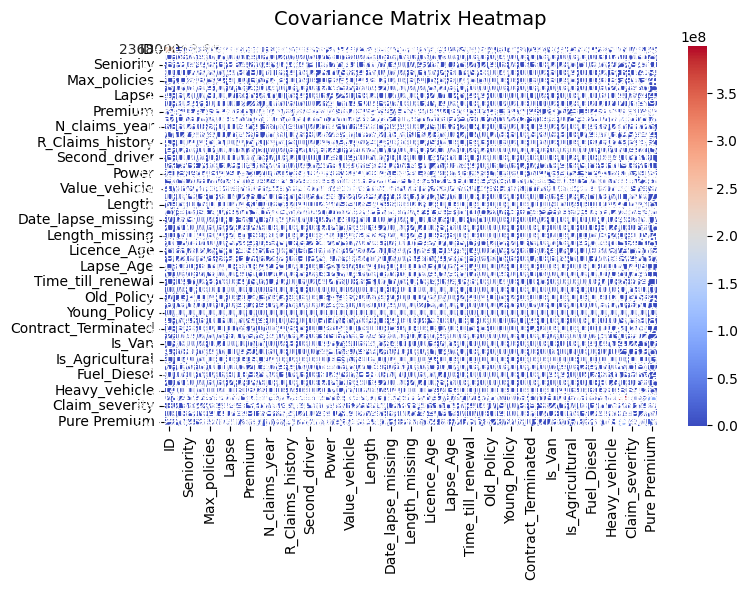

In [ ]:
cov_matrix = df_motor.cov()

plt.figure(figsize=(8, 6))
sns.heatmap(
    cov_matrix, 
    annot=True,      # Displays the numerical covariance values on the plot
    fmt=".2f",       # Formats the numbers to 2 decimal places
    cmap="coolwarm", # Balanced color scheme for positive/negative relationships
    linewidths=0.5   # Adds lines between cells for better readability
)

plt.title("Covariance Matrix Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

In [ ]:
groups = ['Type_risk','Date_lapse_missing', 'N_doors', 'Second_driver','Old_Policy']
group_of_interest = groups[0]
group_filter = 1
df_motor[group_of_interest].unique()

x1, y1, x2, y2 = plot_df(df_motor, x_col='Policy_Age', y_col='', title='plot of Pure Premium vs ', column='')
df_plotting = pd.DataFrame({
    "x": x1,
    "y": y1
})

sns.set_theme(style="darkgrid")

sns.scatterplot(data=df_plotting, x='x', y='y', color='royalblue', s=80, label='Data Points')


plt.title(f'Plot of Policy age against Missingness in length when {group_of_interest} is {group_filter}', fontsize=14, pad=15)
plt.xlabel('Policy Age', fontsize=11)
plt.ylabel('Missingness', fontsize=11)

plt.show()

# Foundational Equations Used in Actuarial Insurance Pricing

## 1. Claim Frequency and Severity

### Claim Frequency

Measures how often claims occur relative to the number of policies insured.

$$
\lambda = \frac{\text{Number of Claims}}{\text{Number of Policies}}
$$

### Claim Severity

Measures the average monetary cost of an individual claim.

$$
E[X] = \frac{\text{Total Cost of Claims}}{\text{Number of Claims}}
$$

### Expected Claims Cost (Pure Premium)

The expected claims cost per policy is calculated by multiplying claim frequency by claim severity.

$$
\boxed{E[S] = \lambda E[X]}
$$

Where:
- $S$ = Aggregate claims cost.
- $\lambda$ = Expected number of claims per policy.
- $X$ = Cost of an individual claim.
- $E[X]$ = Expected claim severity.

---

## 2. Probability Distributions for Claims

### Poisson Distribution (Claim Frequency)

Models the probability of observing a particular number of claims over a specified period.

$$
\boxed{P(N=n)=\frac{e^{-\lambda}\lambda^n}{n!}}
$$

Where:
- $N$ = Number of claims.
- $n$ = Specific number of claims.
- $\lambda$ = Expected number of claims.
- $e$ = Euler's number.

The probability of receiving zero claims is:

$$
P(N=0)=e^{-\lambda}
$$

### Lognormal Distribution (Claim Severity)

Models positive, right-skewed claim amounts where large claims occur less frequently.

$$
\ln(X)\sim N(\mu,\sigma^2)
$$

Where:
- $X$ = Claim severity.
- $\mu$ = Mean of the logarithm of claim severity.
- $\sigma^2$ = Variance of the logarithm of claim severity.

### Gamma Distribution (Claim Severity)

An alternative distribution for modelling positive, right-skewed claim amounts.

$$
f(x)=\frac{x^{\alpha-1}e^{-x/\theta}}{\Gamma(\alpha)\theta^\alpha}, \quad x>0
$$

Where:
- $\alpha$ = Shape parameter.
- $\theta$ = Scale parameter.
- $\Gamma(\alpha)$ = Gamma function.

---

## 3. Aggregate Claims

### Total Aggregate Claims

Represents the total monetary value of all claims received by an insurer.

$$
\boxed{S=\sum_{i=1}^{N}X_i}
$$

Where:
- $S$ = Total aggregate claims.
- $N$ = Number of claims.
- $X_i$ = Cost of the individual $i$-th claim.

### Expected Aggregate Claims

Assuming claim frequency and severity are independent:

$$
\boxed{E[S]=E[N]E[X]}
$$

For a Poisson frequency model:

$$
E[S]=\lambda E[X]
$$

### Variance of Aggregate Claims

Assuming independent and identically distributed claim severities, and independence between frequency and severity:

$$
\boxed{\operatorname{Var}(S)=E[N]\operatorname{Var}(X)+\operatorname{Var}(N)(E[X])^2}
$$

For a Poisson frequency model:

$$
\boxed{\operatorname{Var}(S)=\lambda E[X^2]}
$$

This measures the uncertainty surrounding the total expected claims cost.

---

## 4. Generalised Linear Models (GLMs)

GLMs allow insurers to estimate how customer characteristics influence expected claim frequency and severity.

### Poisson GLM (Claim Frequency)

$$
\boxed{\log(\lambda_i)=\beta_0+\sum_{j=1}^{p}\beta_jx_{ij}}
$$

Rearranging to calculate expected claim frequency:

$$
\lambda_i=e^{\beta_0+\sum_{j=1}^{p}\beta_jx_{ij}}
$$

Where:
- $\lambda_i$ = Expected claim frequency for customer $i$.
- $\beta_0$ = Intercept.
- $\beta_j$ = Model coefficients.
- $x_{ij}$ = Customer characteristics or predictor variables.
- $p$ = Number of predictor variables.

### Gamma GLM (Claim Severity)

Using a logarithmic link function:

$$
\boxed{\log(E[X_i])=\gamma_0+\sum_{j=1}^{p}\gamma_jx_{ij}}
$$

Where:
- $E[X_i]$ = Expected claim severity for customer $i$.
- $\gamma_0$ = Intercept.
- $\gamma_j$ = Model coefficients.
- $x_{ij}$ = Customer characteristics or predictor variables.

### Customer-Specific Pure Premium

Combining the frequency and severity models:

$$
\boxed{P_i=\lambda_i E[X_i]}
$$

Where:
- $P_i$ = Expected claims cost for customer $i$.
- $\lambda_i$ = Predicted claim frequency.
- $E[X_i]$ = Predicted claim severity.

---

## 5. Deductibles and Insurance Limits

Insurance policies often include excesses (deductibles) and maximum payment limits.

### Insurer's Claim Payment

$$
\boxed{Y=\min(\max(X-d,0),L)}
$$

Where:
- $Y$ = Amount paid by the insurer.
- $X$ = Total claim amount.
- $d$ = Policy excess or deductible.
- $L$ = Maximum insurer payment limit.

### Expected Insurer Claim Payment

$$
\boxed{E[Y]=\int_d^{d+L}P(X>x)\,dx}
$$

This calculates the expected amount paid by the insurer after accounting for the deductible and policy limit.

---

## 6. Final Insurance Premium

The pure premium only covers expected claims. Insurers must also account for operating expenses and their target profit margin.

### Gross Insurance Premium

$$
\boxed{P=\frac{EL+F}{1-v-m}}
$$

Where:
- $P$ = Gross insurance premium.
- $EL$ = Expected claims cost (pure premium).
- $F$ = Fixed expenses per policy.
- $v$ = Variable expenses as a proportion of premium.
- $m$ = Target profit margin as a proportion of premium.

### Example

Suppose an insurer estimates:

| Component | Value |
|---|---:|
| Expected claims cost ($EL$) | £480 |
| Fixed expenses ($F$) | £60 |
| Variable expenses ($v$) | 20% |
| Target profit margin ($m$) | 5% |

The gross premium is:

$$
P=\frac{480+60}{1-0.20-0.05}
$$

$$
\boxed{P=£720}
$$

---

## 7. Overall Actuarial Pricing Process

The general process combines the above equations:

1. **Historical data:** Collect policyholder characteristics, previous claims and claim amounts.
2. **Frequency modelling:** Estimate the expected number of claims using distributions such as Poisson or Negative Binomial.
3. **Severity modelling:** Estimate the expected cost of claims using distributions such as Gamma or Lognormal.
4. **Expected claims cost:** Combine frequency and severity to calculate the pure premium.
5. **Policy adjustments:** Account for deductibles, limits, inflation and reinsurance.
6. **Final premium:** Include expenses, risk allowances and the insurer's target profit.

The central equation connecting the process is:

$$
\boxed{\text{Expected Claims Cost}=\text{Frequency}\times\text{Severity}}
$$

---

## 8. Additional Actuarial Concepts Worth Learning

| Concept | Application |
|---|---|
| Expected value | Estimating average future claims costs. |
| Variance | Quantifying uncertainty in claims. |
| Poisson distribution | Modelling claim frequency. |
| Negative Binomial distribution | Modelling overdispersed claim frequency. |
| Gamma distribution | Modelling claim severity. |
| Lognormal distribution | Modelling right-skewed claim severity. |
| Compound distributions | Modelling total aggregate losses. |
| Generalised Linear Models | Predicting customer-specific claim frequency and severity. |
| Maximum Likelihood Estimation | Estimating statistical model parameters. |
| Chain Ladder Method | Estimating outstanding insurance claims (reserving). |

**Important distinction:** Pricing estimates the expected cost of future claims to determine premiums. Reserving estimates the outstanding cost of claims that have already occurred but may not yet have been fully settled.